In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/data.csv", sep=";")

df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
df.shape

(4424, 37)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [5]:
df.columns

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd

In [6]:
df["Application order"].unique()

array([5, 1, 2, 4, 3, 6, 9, 0])

In [7]:
df_clean = df.copy()

In [8]:
df_clean.columns = (df_clean.columns
                    .str.strip()
                    .str.lower()
                    .str.replace(" ", "_")
                    .str.replace("/", "_")
                    .str.replace("'", "")
                    .str.replace("(", "", regex=False)
                    .str.replace(")", "", regex=False))

In [9]:
df_clean = df_clean.rename(columns={"nacionality": "nationality"})

In [10]:
df_clean.columns

Index(['marital_status', 'application_mode', 'application_order', 'course',
       'daytime_evening_attendance', 'previous_qualification',
       'previous_qualification_grade', 'nationality', 'mothers_qualification',
       'fathers_qualification', 'mothers_occupation', 'fathers_occupation',
       'admission_grade', 'displaced', 'educational_special_needs', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'age_at_enrollment', 'international',
       'curricular_units_1st_sem_credited',
       'curricular_units_1st_sem_enrolled',
       'curricular_units_1st_sem_evaluations',
       'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade',
       'curricular_units_1st_sem_without_evaluations',
       'curricular_units_2nd_sem_credited',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_evaluations',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'curricular_units_2nd_sem_wit

In [11]:
df_clean.duplicated().sum()

np.int64(0)

In [12]:
df_clean.isna().sum()

marital_status                                  0
application_mode                                0
application_order                               0
course                                          0
daytime_evening_attendance                      0
previous_qualification                          0
previous_qualification_grade                    0
nationality                                     0
mothers_qualification                           0
fathers_qualification                           0
mothers_occupation                              0
fathers_occupation                              0
admission_grade                                 0
displaced                                       0
educational_special_needs                       0
debtor                                          0
tuition_fees_up_to_date                         0
gender                                          0
scholarship_holder                              0
age_at_enrollment                               0


In [13]:
df_clean.dtypes

marital_status                                    int64
application_mode                                  int64
application_order                                 int64
course                                            int64
daytime_evening_attendance                        int64
previous_qualification                            int64
previous_qualification_grade                    float64
nationality                                       int64
mothers_qualification                             int64
fathers_qualification                             int64
mothers_occupation                                int64
fathers_occupation                                int64
admission_grade                                 float64
displaced                                         int64
educational_special_needs                         int64
debtor                                            int64
tuition_fees_up_to_date                           int64
gender                                          

In [14]:
df_clean.nunique()

marital_status                                    6
application_mode                                 18
application_order                                 8
course                                           17
daytime_evening_attendance                        2
previous_qualification                           17
previous_qualification_grade                    101
nationality                                      21
mothers_qualification                            29
fathers_qualification                            34
mothers_occupation                               32
fathers_occupation                               46
admission_grade                                 620
displaced                                         2
educational_special_needs                         2
debtor                                            2
tuition_fees_up_to_date                           2
gender                                            2
scholarship_holder                                2
age_at_enrol

In [15]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
marital_status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
application_mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
application_order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
daytime_evening_attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
previous_qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
nationality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
mothers_qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
fathers_qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [16]:
(df_clean.select_dtypes(include="number") == 0).sum()

marital_status                                     0
application_mode                                   0
application_order                                  1
course                                             0
daytime_evening_attendance                       483
previous_qualification                             0
previous_qualification_grade                       0
nationality                                        0
mothers_qualification                              0
fathers_qualification                              0
mothers_occupation                               144
fathers_occupation                               128
admission_grade                                    0
displaced                                       1998
educational_special_needs                       4373
debtor                                          3921
tuition_fees_up_to_date                          528
gender                                          2868
scholarship_holder                            

In [17]:
df_clean["target"] = df_clean["target"].str.strip()
df_clean["target"].value_counts()

target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [18]:
df_clean["target"].value_counts(normalize=True) * 100

target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64

In [19]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Duplicates:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isna().sum().sum())

Original shape: (4424, 37)
Cleaned shape: (4424, 37)
Duplicates: 0
Missing values: 0


In [20]:
df_clean.head()

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Cleaning and clustering data from Student Dropout Columns Marital Status, 

In [21]:
# Create new application order with 9 being top preference
df_clean["application_reordered"] = (df_clean["application_order"] - 10).abs()
df_clean = df_clean.drop(['application_order'], axis=1)

In [22]:
df_clean

,marital_status,application_mode,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,...,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target,application_reordered
0,1,17,171,1,1,122.0,1,19,12,5,...,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,5
1,1,15,9254,1,1,160.0,1,1,3,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,9
2,1,1,9070,1,1,122.0,1,37,37,9,...,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,5
3,1,17,9773,1,1,122.0,1,38,37,5,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,8
4,2,39,8014,0,1,100.0,1,37,38,9,...,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,9773,1,1,125.0,1,1,1,5,...,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate,4
4420,1,1,9773,1,1,120.0,105,1,1,9,...,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout,8
4421,1,1,9500,1,1,154.0,1,37,37,9,...,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout,9
4422,1,1,9147,1,1,180.0,1,37,37,7,...,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate,9


In [23]:
df_clean["application_reordered"].unique()

array([ 5,  9,  8,  6,  7,  4,  1, 10])

In [24]:
df_clean["application_mode"].value_counts()

application_mode
1     1708
17     872
39     785
43     312
44     213
7      139
18     124
42      77
51      59
16      38
53      35
15      30
5       16
10      10
2        3
57       1
26       1
27       1
Name: count, dtype: int64

In [25]:
mode_groups = {
    "1st phase special (islands)": [5, 16],
    "Transfer / change": [42, 43, 51, 57],
    "Prior qualification": [7, 44, 53],
    "Ordinances": [2, 10, 26, 27],
    "1st phase - general contingent": [1],
    "2nd phase - general contingent": [17],
    "Over 23 years old": [39],
    "3rd phase - general contingent": [18],
    "International student (bachelor)": [15],
}

code_to_group = {code: group for group, codes in mode_groups.items() for code in codes}
df_clean["application_mode_group"] = df_clean["application_mode"].replace(code_to_group).astype(str)

In [26]:
print(df_clean["application_mode_group"].isna().sum())   # should be 0
df_clean["application_mode_group"].value_counts()

0


application_mode_group
1st phase - general contingent      1708
2nd phase - general contingent       872
Over 23 years old                    785
Transfer / change                    449
Prior qualification                  387
3rd phase - general contingent       124
1st phase special (islands)           54
International student (bachelor)      30
Ordinances                            15
Name: count, dtype: int64

In [27]:
marriage_groups = {
    "single": [1],
    "married": [2],
    "widower": [3],
    "divorced": [4],
    "facto union": [5],
    "legally separated": [6],
}

code_to_marriage = {code: group for group, codes in marriage_groups.items() for code in codes}
df_clean["relationship_group"] = df_clean["marital_status"].replace(code_to_marriage).astype(str)

# Check: every code should have been converted, so no numbers should be left
print(df_clean["relationship_group"].value_counts())

relationship_group
single               3919
married               379
divorced               91
facto union            25
legally separated       6
widower                 4
Name: count, dtype: int64


In [ ]:
marriage_groups = {
    "single": [1],
    "married": [2],
    "widower": [3],
    "divorced": [4],
    "facto union": [5],
    "legally separated": [6],
}

code_to_marriage = {code: group for group, codes in marriage_groups.items() for code in codes}
df_clean["relationship_group"] = df_clean["marital_status"].replace(code_to_marriage).astype(str)

# Check: every code should have been converted, so no numbers should be left
print(df_clean["relationship_group"].value_counts())

In [29]:
course_groups = {
    "Biofuel Production Technologies": [33],
    "Animation and Multimedia Design": [171],
    "Social Service (evening attendance)": [8014],
    "Agronomy": [9003],
    "Communication Design": [9070],
    "Veterinary Nursing": [9085],
    "Informatics Engineering": [9119],
    "Equinculture": [9130],
    "Management": [9147],
    "Social Service": [9238],
    "Tourism": [9254],
    "Nursing": [9500],
    "Oral Hygiene": [9556],
    "Advertising and Marketing Management": [9670],
    "Journalism and Communication": [9773],
    "Basic Education": [9853],
    "Management (evening attendance)": [9991],
}

code_to_course = {code: group for group, codes in course_groups.items() for code in codes}
df_clean["course_name"] = df_clean["course"].replace(code_to_course).astype(str)

In [30]:
qualification_groups = {
    "Secondary education": [1],
    "Secondary incomplete": [9, 10, 12, 14, 15],
    "Basic education": [19, 38],
    "Technical / vocational": [39, 42],
    "Frequency of higher education": [6],
    "Bachelor-level degree": [2, 3, 40],
    "Postgraduate": [4, 5, 43],
}

code_to_qualification = {code: group for group, codes in qualification_groups.items() for code in codes}
df_clean["previous_qualification_group"] = (
    df_clean["previous_qualification"].replace(code_to_qualification).astype(str)
)

# Check: every code should have been converted, so no numbers should be left
print(df_clean["previous_qualification_group"].value_counts())

previous_qualification_group
Secondary education              3717
Technical / vocational            255
Bachelor-level degree             189
Basic education                   169
Secondary incomplete               63
Frequency of higher education      16
Postgraduate                       15
Name: count, dtype: int64


In [31]:
df_clean

,marital_status,application_mode,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,...,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target,application_reordered,application_mode_group,relationship_group,course_name,previous_qualification_group
0,1,17,171,1,1,122.0,1,19,12,5,...,0,10.8,1.4,1.74,Dropout,5,2nd phase - general contingent,single,Animation and Multimedia Design,Secondary education
1,1,15,9254,1,1,160.0,1,1,3,3,...,0,13.9,-0.3,0.79,Graduate,9,International student (bachelor),single,Tourism,Secondary education
2,1,1,9070,1,1,122.0,1,37,37,9,...,0,10.8,1.4,1.74,Dropout,5,1st phase - general contingent,single,Communication Design,Secondary education
3,1,17,9773,1,1,122.0,1,38,37,5,...,0,9.4,-0.8,-3.12,Graduate,8,2nd phase - general contingent,single,Journalism and Communication,Secondary education
4,2,39,8014,0,1,100.0,1,37,38,9,...,0,13.9,-0.3,0.79,Graduate,9,Over 23 years old,married,Social Service (evening attendance),Secondary education
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,9773,1,1,125.0,1,1,1,5,...,0,15.5,2.8,-4.06,Graduate,4,1st phase - general contingent,single,Journalism and Communication,Secondary education
4420,1,1,9773,1,1,120.0,105,1,1,9,...,0,11.1,0.6,2.02,Dropout,8,1st phase - general contingent,single,Journalism and Communication,Secondary education
4421,1,1,9500,1,1,154.0,1,37,37,9,...,0,13.9,-0.3,0.79,Dropout,9,1st phase - general contingent,single,Nursing,Secondary education
4422,1,1,9147,1,1,180.0,1,37,37,7,...,0,9.4,-0.8,-3.12,Graduate,9,1st phase - general contingent,single,Management,Secondary education


In [34]:
df_clean_cat =df_clean.drop(['marital_status', 'application_mode', 'course', 'previous_qualification'], axis=1)
df_clean_cat

,daytime_evening_attendance,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,...,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target,application_reordered,application_mode_group,relationship_group,course_name,previous_qualification_group
0,1,122.0,1,19,12,5,9,127.3,1,0,...,0,10.8,1.4,1.74,Dropout,5,2nd phase - general contingent,single,Animation and Multimedia Design,Secondary education
1,1,160.0,1,1,3,3,3,142.5,1,0,...,0,13.9,-0.3,0.79,Graduate,9,International student (bachelor),single,Tourism,Secondary education
2,1,122.0,1,37,37,9,9,124.8,1,0,...,0,10.8,1.4,1.74,Dropout,5,1st phase - general contingent,single,Communication Design,Secondary education
3,1,122.0,1,38,37,5,3,119.6,1,0,...,0,9.4,-0.8,-3.12,Graduate,8,2nd phase - general contingent,single,Journalism and Communication,Secondary education
4,0,100.0,1,37,38,9,9,141.5,0,0,...,0,13.9,-0.3,0.79,Graduate,9,Over 23 years old,married,Social Service (evening attendance),Secondary education
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,125.0,1,1,1,5,4,122.2,0,0,...,0,15.5,2.8,-4.06,Graduate,4,1st phase - general contingent,single,Journalism and Communication,Secondary education
4420,1,120.0,105,1,1,9,9,119.0,1,0,...,0,11.1,0.6,2.02,Dropout,8,1st phase - general contingent,single,Journalism and Communication,Secondary education
4421,1,154.0,1,37,37,9,9,149.5,1,0,...,0,13.9,-0.3,0.79,Dropout,9,1st phase - general contingent,single,Nursing,Secondary education
4422,1,180.0,1,37,37,7,4,153.8,1,0,...,0,9.4,-0.8,-3.12,Graduate,9,1st phase - general contingent,single,Management,Secondary education


## Run Split Test and Processs

In [36]:
#Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 0

In [37]:
# #Perform Train Test Split on df_clean_cat
X = df_clean_cat.drop(columns='target')
y = df_clean_cat['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=0, stratify=y
)

In [48]:
#Define nominal features for HomePlanet, Destination, and Cabin_section 
nominal_features = ['application_mode_group', 'relationship_group', 'course_name', 'previous_qualification_group']

nominal_pipeline = Pipeline([('encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

processing = ColumnTransformer([
    ('nominal', nominal_pipeline, nominal_features)
])

full_pipeline = Pipeline([('preprocess', processing), ('model', KNeighborsClassifier(n_neighbors=5))])

full_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Dropout','Enrolled','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['daytime_evening_attendance','previous_qualification_grade','nationality', ...,'relationship_group','course_name','previous_qualification_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

In [49]:
print('Training accuracy:', round(full_pipeline.score(X_train, y_train), 3))
print('Test accuracy:', round(full_pipeline.score(X_test, y_test), 3))

Training accuracy: 0.577
Test accuracy: 0.549


In [43]:
# predictions for full pipeline
y_pred_train_knn = full_pipeline.predict(X_train)
y_pred_test_knn  = full_pipeline.predict(X_test)

comparison_students = pd.DataFrame({
    "actual_student_status": y_test,
    "predicted_student_status": pd.Series(y_pred_test_knn, index=y_test.index),
})

display(comparison_students.head(10))

,actual_student_status,predicted_student_status
1093,Dropout,Dropout
2167,Graduate,Graduate
606,Dropout,Dropout
2382,Dropout,Dropout
2703,Dropout,Graduate
3773,Dropout,Dropout
908,Enrolled,Graduate
4045,Dropout,Graduate
999,Dropout,Graduate
2360,Enrolled,Dropout


In [50]:
classification_metrics = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_train, y_pred_train_knn),
        "Precision (macro)": precision_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (macro)": recall_score(y_train, y_pred_train_knn, average='macro'),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test, y_pred_test_knn),
        "Precision (macro)": precision_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (macro)": recall_score(y_test, y_pred_test_knn, average='macro'),
    },
})
display(classification_metrics.round(3))

,Training,Test
Accuracy,0.577,0.549
Precision (macro),0.515,0.500
Recall (macro),0.486,0.456


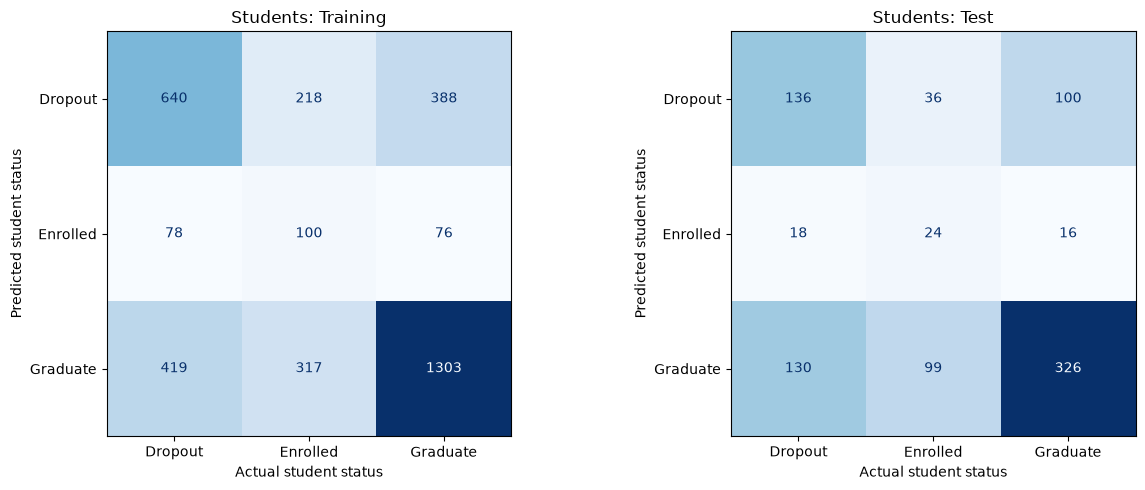

In [52]:
# One class order, used by both the matrix and the labels
class_order = ["Dropout", "Enrolled", "Graduate"]

# Compute confusion matrices for both datasets
cm_train = confusion_matrix(y_train, y_pred_train_knn, labels=class_order)
cm_test  = confusion_matrix(y_test,  y_pred_test_knn,  labels=class_order)

# Plot the confusion matrices: train vs test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, split_name in zip(axes, [cm_train, cm_test], ["Training", "Test"]):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=class_order,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual student status")
    ax.set_ylabel("Predicted student status")
    ax.set_title(f"Students: {split_name}")

plt.tight_layout()
plt.show()

In [53]:
df_binary = df_clean_cat[df_clean_cat["target"] != "Enrolled"]

In [55]:
# #Perform Train Test Split on df_clean_cat
X_bi = df_binary.drop(columns='target')
y_bi = df_binary['target']
X_bi_train, X_bi_test, y_bi_train, y_bi_test = train_test_split(
    X_bi, y_bi, test_size=0.2,
    random_state=0, stratify=y_bi
)

In [57]:
#Define nominal features for HomePlanet, Destination, and Cabin_section 
nominal_features = ['application_mode_group', 'relationship_group', 'course_name', 'previous_qualification_group']

nominal_pipeline_bi = Pipeline([('encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

processing_bi = ColumnTransformer([
    ('nominal', nominal_pipeline, nominal_features)
])

full_pipeline_bi = Pipeline([('preprocess', processing_bi), ('model', KNeighborsClassifier(n_neighbors=5))])

full_pipeline_bi.fit(X_bi_train, y_bi_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['daytime_evening_attendance','previous_qualification_grade','nationality', ...,'relationship_group','course_name','previous_qualification_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [58]:
print('Training accuracy:', round(full_pipeline_bi.score(X_train, y_train), 3))
print('Test accuracy:', round(full_pipeline_bi.score(X_test, y_test), 3))

Training accuracy: 0.719
Test accuracy: 0.674


In [59]:
# predictions for full pipeline
y_pred_train_knn_bi = full_pipeline_bi.predict(X_bi_train)
y_pred_test_knn_bi  = full_pipeline_bi.predict(X_bi_test)

comparison_students_bi = pd.DataFrame({
    "actual_student_status": y_bi_test,
    "predicted_student_status": pd.Series(y_pred_test_knn_bi, index=y_bi_test.index),
})

display(comparison_students_bi.head(10))

,actual_student_status,predicted_student_status
3989,Graduate,Graduate
959,Dropout,Graduate
265,Graduate,Graduate
243,Dropout,Dropout
3919,Graduate,Graduate
1531,Graduate,Graduate
144,Graduate,Graduate
1377,Graduate,Dropout
683,Dropout,Dropout
2028,Graduate,Graduate


In [64]:
classification_metrics_bi = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_bi_train, y_pred_train_knn_bi),
        "Precision": precision_score(y_bi_train, y_pred_train_knn_bi, average='macro'),
        "Recall": recall_score(y_bi_train, y_pred_train_knn_bi, average='macro'),
    },
    "Test": {
        "Accuracy": accuracy_score(y_bi_test, y_pred_test_knn_bi),
        "Precision": precision_score(y_bi_test, y_pred_test_knn_bi, average='macro'),
        "Recall": recall_score(y_bi_test, y_pred_test_knn_bi, average='macro'),
    },
})
display(classification_metrics_bi.round(3))

,Training,Test
Accuracy,0.719,0.674
Precision,0.707,0.655
Recall,0.689,0.636


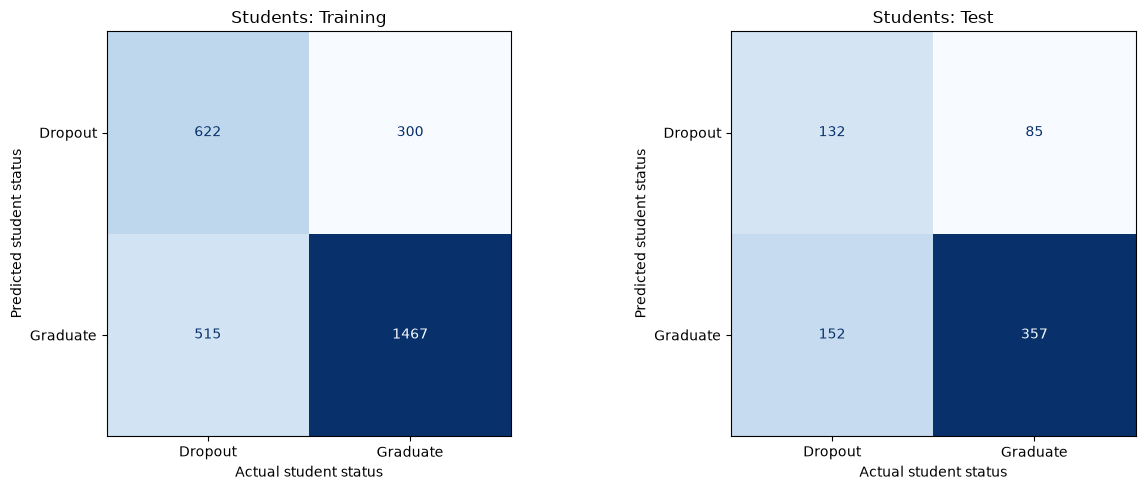

In [66]:
# One class order, used by both the matrix and the labels
class_order = ["Dropout", "Graduate"]

# Compute confusion matrices for both datasets
cm_bi_train = confusion_matrix(y_bi_train, y_pred_train_knn_bi, labels=class_order)
cm_bi_test  = confusion_matrix(y_bi_test,  y_pred_test_knn_bi,  labels=class_order)

# Plot the confusion matrices: train vs test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, split_name in zip(axes, [cm_bi_train, cm_bi_test], ["Training", "Test"]):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=class_order,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual student status")
    ax.set_ylabel("Predicted student status")
    ax.set_title(f"Students: {split_name}")

plt.tight_layout()
plt.show()